# 4. lecke – bináris osztályozás: depresszió

**Cél:** tanulási célú osztályozó készítése a `Student_Depression_Dataset.csv` adataiból. A pozitív osztály a `Depression = Yes`, amelyet 1-re kódolunk; a `No` érték kódja 0. A jegyzetfüzet minden adatból tanuló lépést kizárólag a tanító részen illeszt, és a tesztrészt csak a 10. fejezetben használja.

## 1. Kérdés és célváltozó

A kérdés az, hogy a megadott 12 jellemző alapján mennyire rangsorolhatók a `Depression = Yes` címkéjű esetek; a pozitív osztály tehát a `Yes`, kódja 1. **Feltételezés:** egy téves riasztás (a modell `Yes`-t jelez, miközben a címke `No`) fölösleges további figyelmet és erőforrást igényelhet; egy kihagyott pozitív eset (a modell `No`-t jelez, miközben a címke `Yes`) késleltetheti a segítség felajánlását, ezért ezt súlyosabbnak tekintjük. Ezek a költségek nem szerepelnek mért adatként, hanem a feladat értelmezéséhez rögzített feltételezések.

## 2. Feltáró adatelemzés

Először az eredeti fájlt olvassuk be, és a tényleges sor-/oszlopszámot, oszloptípusokat, valamint a célváltozó megoszlását mérjük meg. A két ábra a címke darabszámát és az életkor szerinti eloszlást mutatja; ezek leíró ábrák, nem modellválasztási eszközök.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# A fájl a jegyzetfüzettel egy mappában van; a második útvonal a gyökérből futtatást kezeli.
data_path = Path("Student_Depression_Dataset.csv")
if not data_path.exists():
    data_path = Path("lesson 4") / "Student_Depression_Dataset.csv"
if not data_path.is_file():
    raise FileNotFoundError(f"Nem található az adatfájl: {data_path.resolve()}")

df = pd.read_csv(data_path)
TARGET = "Depression"
EXPECTED_FEATURES = [
    "Gender", "Age", "Family_background", "Relationship_status",
    "Marital_status", "Living_style", "Current_semester", "CGPA",
    "friend_circle", "Health_condition", "Cost_without_study", "Home_division",
]
if TARGET not in df.columns:
    raise ValueError(f"Hiányzik a céloszlop: {TARGET}")
if set(df.columns) != set(EXPECTED_FEATURES + [TARGET]):
    raise ValueError(f"A tényleges oszlopok eltérnek a feladatban megadottaktól: {df.columns.tolist()}")
if set(df[TARGET].dropna().unique()) != {"Yes", "No"}:
    raise ValueError(f"Váratlan célcímkék: {df[TARGET].dropna().unique().tolist()}")

print(f"A tábla mérete: {df.shape[0]} sor × {df.shape[1]} oszlop.")
print("Oszloptípusok:")
print(df.dtypes.to_string())
class_counts = df[TARGET].value_counts().reindex(["No", "Yes"], fill_value=0)
positive_rate = (df[TARGET] == "Yes").mean()
print()
print("Célosztályok darabszáma:")
print(class_counts.to_string())
print(f"A pozitív (Yes) osztály aránya: {positive_rate:.4%} ({class_counts['Yes']}/{len(df)} sor).")

A tábla mérete: 4464 sor × 13 oszlop.
Oszloptípusok:
Gender                     str
Age                      int64
Family_background          str
Relationship_status        str
Marital_status             str
Living_style               str
Current_semester         int64
CGPA                   float64
friend_circle              str
Health_condition           str
Cost_without_study       int64
Home_division              str
Depression                 str

Célosztályok darabszáma:
Depression
No     3263
Yes    1201
A pozitív (Yes) osztály aránya: 26.9041% (1201/4464 sor).


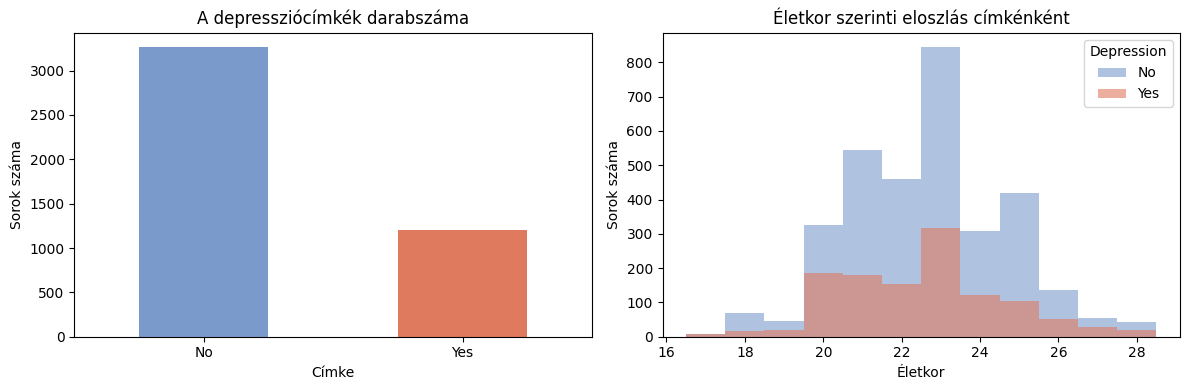

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
class_counts.plot(kind="bar", color=["#7b9acc", "#e07a5f"], ax=axes[0])
axes[0].set_title("A depressziócímkék darabszáma")
axes[0].set_xlabel("Címke")
axes[0].set_ylabel("Sorok száma")
axes[0].tick_params(axis="x", rotation=0)

for label, color in [("No", "#7b9acc"), ("Yes", "#e07a5f")]:
    axes[1].hist(df.loc[df[TARGET] == label, "Age"], bins=np.arange(df["Age"].min() - 0.5, df["Age"].max() + 1.5, 1), alpha=0.6, label=label, color=color)
axes[1].set_title("Életkor szerinti eloszlás címkénként")
axes[1].set_xlabel("Életkor")
axes[1].set_ylabel("Sorok száma")
axes[1].legend(title="Depression")
fig.tight_layout()
plt.show()

## 3. Tisztítás és adatellenőrzés

A hiányzó értékeket oszloponként és a teljes duplikált sorokat külön megszámoljuk, a címkeértékeket pedig ellenőrizzük. Nem törlünk és nem töltünk ki sort vagy mezőt automatikusan: ha az ellenőrzés nem nulla hiányt vagy duplikátumot mutat, azt láthatóan jelentjük, és a notebook megáll, amíg nincs indokolt döntés. A jelen feladatban az imputálás csak a későbbi pipeline-ok részeként szerepel, tanító adatokon illesztve.

In [3]:
missing_by_column = df.isna().sum()
duplicate_rows = int(df.duplicated().sum())
print("Hiányzó értékek oszloponként:")
print(missing_by_column.to_string())
print(f"Hiányzó cellák összesen: {int(missing_by_column.sum())}.")
print(f"Teljesen duplikált sorok: {duplicate_rows}.")
print(f"Célcímkék: {sorted(df[TARGET].dropna().unique().tolist())}.")

if missing_by_column.sum() != 0 or duplicate_rows != 0:
    raise ValueError("Az adatellenőrzés hiányt vagy duplikátumot talált; indokolt tisztítási döntés szükséges.")
print("Döntés: a 0 hiányzó érték és 0 duplikált sor miatt egyetlen sort vagy mezőt sem törlünk és nem töltünk ki.")

X = df[EXPECTED_FEATURES].copy()
y = df[TARGET].map({"No": 0, "Yes": 1}).astype("int8")
if y.isna().any():
    raise ValueError("A célváltozó kódolása után hiányzó címke keletkezett.")
print(f"Célkódolás: No=0, Yes=1; az 1-es címke aránya {y.mean():.4%} ({int(y.sum())}/{len(y)}).")

Hiányzó értékek oszloponként:
Gender                 0
Age                    0
Family_background      0
Relationship_status    0
Marital_status         0
Living_style           0
Current_semester       0
CGPA                   0
friend_circle          0
Health_condition       0
Cost_without_study     0
Home_division          0
Depression             0
Hiányzó cellák összesen: 0.
Teljesen duplikált sorok: 0.
Célcímkék: ['No', 'Yes'].
Döntés: a 0 hiányzó érték és 0 duplikált sor miatt egyetlen sort vagy mezőt sem törlünk és nem töltünk ki.
Célkódolás: No=0, Yes=1; az 1-es címke aránya 26.9041% (1201/4464).


## 4. Felosztás – először a tanító- és tesztrész

A 4 464 sorból 20%-ot végső tesztre tartunk fenn, a címkearányt rétegzéssel őrizzük, a reprodukálhatósághoz pedig 42-es véletlenmagot használunk. E pont előtt nem illesztettünk imputálót, skálázót, kódolót vagy modellt; a tesztcímkéket a 10. fejezetig nem kérdezzük le.

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(f"Tanító rész: {len(X_train)} sor; tesztrész: {len(X_test)} sor.")
print(f"Pozitív arány a tanítórészben: {y_train.mean():.4%} ({int(y_train.sum())}/{len(y_train)}).")

Tanító rész: 3571 sor; tesztrész: 893 sor.
Pozitív arány a tanítórészben: 26.9112% (961/3571).


## 5. Előfeldolgozás és modellekhez illesztett kódolás

A numerikus oszlopokat mediánnal imputáló és a logisztikus regresszióhoz standardizáló pipeline kezeli; a kategorikus oszlopokat módusszal imputáljuk. A lineáris modell egy-hot kódolást kap, mert ez nem rendel mesterséges sorrendet a kategóriákhoz; a fákat ordinális kódolással látjuk el, mert a faelágazások számkódokkal dolgoznak, és a bemeneti dimenziót sem sokszorozzuk meg. Bár a jelen fájlban nincs hiány, az imputálók is kizárólag a pipeline-okban, a tanító rész megfelelő hajtásain tanulnak.

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

NUMERIC_COLUMNS = X_train.select_dtypes(include=np.number).columns.tolist()
CATEGORICAL_COLUMNS = [c for c in X_train.columns if c not in NUMERIC_COLUMNS]
print(f"Numerikus jellemzők ({len(NUMERIC_COLUMNS)}): {NUMERIC_COLUMNS}")
print(f"Kategorikus jellemzők ({len(CATEGORICAL_COLUMNS)}): {CATEGORICAL_COLUMNS}")

def make_pipeline(family, X_schema):
    numeric_columns = X_schema.select_dtypes(include=np.number).columns.tolist()
    categorical_columns = [c for c in X_schema.columns if c not in numeric_columns]
    if family == "logistic":
        numeric_pipe = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ])
        categorical_pipe = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore")),
        ])
    else:
        numeric_pipe = Pipeline([("imputer", SimpleImputer(strategy="median"))])
        categorical_pipe = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
        ])
    prep = ColumnTransformer([
        ("numerical", numeric_pipe, numeric_columns),
        ("kategorikus", categorical_pipe, categorical_columns),
    ])
    if family == "dummy":
        classifier = DummyClassifier(strategy="prior")
    elif family == "logistic":
        classifier = LogisticRegression(max_iter=3000, random_state=42)
    elif family == "decision_tree":
        classifier = DecisionTreeClassifier(random_state=42)
    elif family == "random_forest":
        classifier = RandomForestClassifier(
            n_estimators=200, class_weight="balanced_subsample",
            random_state=42, n_jobs=1
        )
    elif family == "xgboost":
        classifier = XGBClassifier(
            objective="binary:logistic", eval_metric="logloss",
            n_estimators=160, learning_rate=0.05, max_depth=3,
            subsample=0.9, colsample_bytree=0.9, reg_lambda=1.0,
            random_state=42, n_jobs=1, verbosity=0
        )
    else:
        raise ValueError(f"Ismeretlen modellcsalád: {family}")
    return Pipeline([("elofeldolgozas", prep), ("modell", classifier)])

Numerikus jellemzők (4): ['Age', 'Current_semester', 'CGPA', 'Cost_without_study']
Kategorikus jellemzők (8): ['Gender', 'Family_background', 'Relationship_status', 'Marital_status', 'Living_style', 'friend_circle', 'Health_condition', 'Home_division']


## 6. Előre rögzített mérőszámok

A fő összehasonlítás a kiegyensúlyozott pontosság (a két osztály visszahívásának átlaga) és a PR-AUC-ként használt átlagos precizitás lesz; ezek jobban láttatják a pozitív osztály teljesítményét, mint a többségi osztályt jutalmazó nyers pontosság. A végső értékeléshez zavarossági mátrixot és a legmagasabb kockázatú 20% pozitív arányát (precision@20%) is közöljük. Az osztályozási küszöböt a tanítórész OOF valószínűségein, kiegyensúlyozott pontosság maximalizálásával választjuk; holtversenyben az 0,5-höz legközelebbi, majd a magasabb küszöb nyer. A felső 20% rangsor szerinti mérőszám, a küszöbös zavarossági mátrix külön mérőszám.

In [6]:
from sklearn.metrics import average_precision_score, balanced_accuracy_score, make_scorer
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

SCORING = {
    "kiegyensulyozott_pontossag": "balanced_accuracy",
    "atlagos_precizitas": "average_precision",
}
CV_N_SPLITS = 5
CV_N_REPEATS = 2
CV = RepeatedStratifiedKFold(n_splits=CV_N_SPLITS, n_repeats=CV_N_REPEATS, random_state=42)
print("Mérőszámok:", ", ".join(SCORING.keys()))
print("Közös keresztvalidáció: 5 hajtás × 2 ismétlés, random_state=42; összesen 10 hajtáspontszám modellenként.")

Mérőszámok: kiegyensulyozott_pontossag, atlagos_precizitas
Közös keresztvalidáció: 5 hajtás × 2 ismétlés, random_state=42; összesen 10 hajtáspontszám modellenként.


## 7. Modell-létra

Azonos, 5 hajtásos és 2 ismétléses rétegzett felosztásokon hasonlítjuk össze az előre rögzített prior-dummyt, a logisztikus regressziót, a döntési fát, a Random Forestet és az XGBoostot. A táblázat minden mérőszámnál a 10 hajtáspontszám átlagát és mintaszórását mutatja; a következő lépésekhez a legnagyobb átlagos PR-AUC-jú családot választjuk, holtversenyben a felsorolt egyszerűbb modell marad.

In [7]:
MODEL_NAMES = ["dummy", "logistic", "decision_tree", "random_forest", "xgboost"]
ladder = {}
rows = []
for family in MODEL_NAMES:
    estimator = make_pipeline(family, X_train)
    scores = cross_validate(
        estimator, X_train, y_train, cv=CV, scoring=SCORING,
        return_train_score=False, n_jobs=1, error_score="raise"
    )
    ladder[family] = scores
    rows.append({
        "modell": family,
        "kiegyensúlyozott pontosság (átlag ± szórás)": f"{scores['test_kiegyensulyozott_pontossag'].mean():.4f} ± {scores['test_kiegyensulyozott_pontossag'].std(ddof=1):.4f}",
        "PR-AUC / átlagos precizitás (átlag ± szórás)": f"{scores['test_atlagos_precizitas'].mean():.4f} ± {scores['test_atlagos_precizitas'].std(ddof=1):.4f}",
    })
ladder_table = pd.DataFrame(rows)
display(ladder_table)
best_family = max(MODEL_NAMES, key=lambda family: ladder[family]["test_atlagos_precizitas"].mean())
print(f"A modell-létra átlagos PR-AUC-ja alapján kiválasztott család: {best_family}.")

,modell,kiegyensúlyozott pontosság (átlag ± szórás),PR-AUC / átlagos precizitás (átlag ± szórás)
0,dummy,0.5000 ± 0.0000,0.2691 ± 0.0004
1,logistic,0.9557 ± 0.0114,0.9851 ± 0.0056
2,decision_tree,0.9869 ± 0.0049,0.9682 ± 0.0094
3,random_forest,0.9782 ± 0.0082,0.9967 ± 0.0023
4,xgboost,0.9810 ± 0.0069,0.9954 ± 0.0030


A modell-létra átlagos PR-AUC-ja alapján kiválasztott család: random_forest.


## 8. Visszacsatolás és két oszlopból képzett új jellemző

A RepeatedStratifiedKFold ismételt teszthajtásai miatt a `cross_val_predict` nem kaphatja meg egyszerre mind a 10 ismételt hajtást: a függvény egyetlen, minden sort pontosan egyszer tesztelő felosztást vár. Ezért ugyanannak az egy közös `CV` objektumnak az 1. és 2. ismétlésből származó 5 hajtását külön-külön adjuk át a `cross_val_predict`-nek, majd soronként átlagoljuk a két valódi, tanításon kívüli becslést. Először megvizsgáljuk a modell-létra vezető modelljének 10 legmagabiztosabb tévesztését.

**Előre rögzített hipotézis:** a `Cost_without_study / Age` arány az életkorhoz viszonyított költségterhelést közelítheti. Az arány nem helyettesíti az eredeti oszlopokat; a két jellemzőből determinisztikusan képződik, és ugyanazon 10 hajtáson mérjük a logisztikus regresszió és az XGBoost páros PR-AUC-különbségét. Csak akkor tekintjük a javulást egyértelműnek, ha a páros átlagos különbség nagyobb, mint a hajtások közötti különbség mintaszórása.

In [8]:
from sklearn.model_selection import cross_val_predict

def repeated_oof_probabilities(estimator, features, labels, splitter):
    fold_groups = [[] for _ in range(CV_N_REPEATS)]
    for fold_number, (train_idx, valid_idx) in enumerate(splitter.split(features, labels)):
        repeat_number = fold_number // CV_N_SPLITS
        fold_groups[repeat_number].append((train_idx, valid_idx))
    repeat_predictions = []
    for folds in fold_groups:
        probabilities = cross_val_predict(
            estimator, features, labels, cv=folds, method="predict_proba", n_jobs=1
        )[:, 1]
        repeat_predictions.append(probabilities)
    return np.mean(np.vstack(repeat_predictions), axis=0)

leader = make_pipeline(best_family, X_train)
oof_leader = repeated_oof_probabilities(leader, X_train, y_train, CV)
oof_hard = (oof_leader >= 0.5).astype(int)
wrong_positions = np.flatnonzero(oof_hard != y_train.to_numpy())
error_confidence = np.where(y_train.to_numpy()[wrong_positions] == 1, 1 - oof_leader[wrong_positions], oof_leader[wrong_positions])
most_confident = wrong_positions[np.argsort(-error_confidence)[:10]]
error_table = X_train.iloc[most_confident].copy()
error_table["valodi_cimke"] = y_train.iloc[most_confident].to_numpy()
error_table["OOF_Yes_valoszinuseg"] = oof_leader[most_confident]
error_table["teves_osztalyozasi_magabiztossag"] = error_confidence[np.argsort(-error_confidence)[:10]]
print(f"A vezető modell OOF tévesztéseinek száma 0,5-ös leíró küszöbnél: {len(wrong_positions)} a {len(y_train)} tanítósorból.")
print("A 10 legmagabiztosabb tévesztés (csak tanítórész, ismételt OOF):")
display(error_table.reset_index(names="eredeti_sorindex"))

A vezető modell OOF tévesztéseinek száma 0,5-ös leíró küszöbnél: 44 a 3571 tanítósorból.
A 10 legmagabiztosabb tévesztés (csak tanítórész, ismételt OOF):


,eredeti_sorindex,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,valodi_cimke,OOF_Yes_valoszinuseg,teves_osztalyozasi_magabiztossag
0,4363,Male,23,Lower Middle class,Complicated,Separated,Bachelor,1,3.46,No,Normal,1577,Chittagong,1,0.0550,0.9450
1,2638,Female,23,Middle class,Complicated,Unmarried,Bachelor,6,3.49,No,Normal,7400,Rangpur,1,0.0575,0.9425
2,3538,Female,20,Middle class,Single,Unmarried,Bachelor,4,3.17,No,Normal,15000,Rajshahi,1,0.0775,0.9225
3,4391,Female,27,Lower Middle class,In a Relationship,Married,Family,10,2.52,No,Normal,3314,Sylhet,1,0.0950,0.9050
4,12,Female,22,Middle class,Complicated,Unmarried,Family,8,3.15,Yes,Abnormal,14437,Dhaka,1,0.0975,0.9025
5,31,Female,21,Rich class,Single,Unmarried,Family,2,2.80,Yes,Normal,19185,Dhaka,1,0.1375,0.8625
6,4162,Male,23,Lower Middle class,Complicated,Unmarried,Family,6,3.40,No,Normal,9899,Sylhet,1,0.1425,0.8575
7,3092,Male,26,Rich class,Single,Unmarried,Family,4,2.89,Yes,Normal,8400,Chittagong,1,0.1675,0.8325
8,1290,Female,23,Rich class,Single,Unmarried,Bachelor,5,2.89,Yes,Normal,26814,Rajshahi,1,0.1725,0.8275
9,2631,Female,21,Middle class,Complicated,Unmarried,Family,6,2.62,No,Normal,5200,Chittagong,1,0.1800,0.8200


In [9]:
def with_cost_per_age(features):
    if (features["Age"] <= 0).any():
        raise ValueError("A Cost_per_age képzéséhez minden Age értéknek pozitívnak kell lennie.")
    result = features.copy()
    result["Cost_per_age"] = result["Cost_without_study"] / result["Age"]
    return result

X_train_ratio = with_cost_per_age(X_train)
print(f"Új jellemző: Cost_per_age = Cost_without_study / Age; tanítósorok: {len(X_train_ratio)}; nulla vagy negatív életkor: {(X_train['Age'] <= 0).sum()}.")
feature_results = {}
feature_rows = []
for family in ["logistic", "xgboost"]:
    base_scores = cross_validate(
        make_pipeline(family, X_train), X_train, y_train, cv=CV,
        scoring="average_precision", return_train_score=False, n_jobs=1, error_score="raise"
    )["test_score"]
    ratio_scores = cross_validate(
        make_pipeline(family, X_train_ratio), X_train_ratio, y_train, cv=CV,
        scoring="average_precision", return_train_score=False, n_jobs=1, error_score="raise"
    )["test_score"]
    differences = ratio_scores - base_scores
    delta_mean = differences.mean()
    delta_std = differences.std(ddof=1)
    feature_results[family] = {"base": base_scores, "ratio": ratio_scores, "delta": differences}
    feature_rows.append({
        "modell": family,
        "eredeti PR-AUC (átlag ± szórás)": f"{base_scores.mean():.4f} ± {base_scores.std(ddof=1):.4f}",
        "aránnyal PR-AUC (átlag ± szórás)": f"{ratio_scores.mean():.4f} ± {ratio_scores.std(ddof=1):.4f}",
        "páros különbség (átlag ± szórás)": f"{delta_mean:+.4f} ± {delta_std:.4f}",
    })
    print(f"{family}: a páros átlagos PR-AUC-különbség {'nagyobb' if delta_mean > delta_std else 'nem nagyobb'} a hajtásszórásnál; {'egyértelmű javulásként kezeljük' if delta_mean > delta_std else 'nem nevezzük valós javulásnak, és nem állítjuk, hogy segített'}.")
display(pd.DataFrame(feature_rows))
use_ratio = {family: bool(feature_results[family]["delta"].mean() > feature_results[family]["delta"].std(ddof=1)) for family in ["logistic", "xgboost"]}
print("A rögzített szabály szerinti új jellemző használata:", use_ratio)

Új jellemző: Cost_per_age = Cost_without_study / Age; tanítósorok: 3571; nulla vagy negatív életkor: 0.


logistic: a páros átlagos PR-AUC-különbség nem nagyobb a hajtásszórásnál; nem nevezzük valós javulásnak, és nem állítjuk, hogy segített.


xgboost: a páros átlagos PR-AUC-különbség nem nagyobb a hajtásszórásnál; nem nevezzük valós javulásnak, és nem állítjuk, hogy segített.


,modell,eredeti PR-AUC (átlag ± szórás),aránnyal PR-AUC (átlag ± szórás),páros különbség (átlag ± szórás)
0,logistic,0.9851 ± 0.0056,0.9851 ± 0.0056,-0.0000 ± 0.0001
1,xgboost,0.9954 ± 0.0030,0.9957 ± 0.0030,+0.0002 ± 0.0003


A rögzített szabály szerinti új jellemző használata: {'logistic': False, 'xgboost': False}


## 9. Hangolás és új, korábban nem használt felosztásokon végzett ellenőrzés

A hangolás alapja kizárólag a tanítórészen mért modell-létra PR-AUC-győztese; a 8. lépésben csak akkor vesszük át az új arányt, ha a páros átlagos különbség meghaladta a hajtásszórást. A `RandomizedSearchCV` PR-AUC-ra, 3 hajtáson, 8 véletlen paraméterjelölttel keres. Ezután a hangolt és az egyszerűbb alapváltozat ugyanazon, új `RepeatedStratifiedKFold(5, 2, random_state=2026)` felosztásokon kap páros összehasonlítást; ha a javulás nem nagyobb a különbség hajtásszórásánál, megtartjuk az egyszerűbb alapváltozatot.

In [10]:
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import RandomizedSearchCV

use_ratio_for_candidate = best_family in use_ratio and use_ratio[best_family]
X_train_candidate = X_train_ratio if use_ratio_for_candidate else X_train
base_candidate = make_pipeline(best_family, X_train_candidate)
if best_family == "xgboost":
    parameter_space = {
        "modell__n_estimators": randint(80, 241),
        "modell__max_depth": randint(2, 6),
        "modell__learning_rate": loguniform(0.02, 0.2),
        "modell__subsample": uniform(0.70, 0.30),
        "modell__colsample_bytree": uniform(0.70, 0.30),
    }
elif best_family == "random_forest":
    parameter_space = {
        "modell__n_estimators": randint(100, 301),
        "modell__max_depth": [None, 5, 10, 15, 20],
        "modell__min_samples_leaf": randint(1, 8),
        "modell__max_features": ["sqrt", 0.7, 1.0],
    }
elif best_family == "decision_tree":
    parameter_space = {
        "modell__max_depth": [None, 3, 5, 8, 12, 16],
        "modell__min_samples_leaf": randint(1, 20),
        "modell__criterion": ["gini", "entropy", "log_loss"],
    }
elif best_family == "logistic":
    parameter_space = {
        "modell__C": loguniform(0.01, 100),
        "modell__class_weight": [None, "balanced"],
    }
else:
    parameter_space = {}

search = RandomizedSearchCV(
    estimator=base_candidate, param_distributions=parameter_space,
    n_iter=8, scoring="average_precision", cv=3,
    random_state=42, n_jobs=1, refit=True, error_score="raise"
)
search.fit(X_train_candidate, y_train)
print(f"Hangolt modellcsalád: {best_family}; jelöltek száma: {search.n_iter}; 3 hajtásos legjobb keresési PR-AUC: {search.best_score_:.4f}.")
print("Legjobb paraméterek:", search.best_params_)

fresh_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=2026)
tuned_candidate = search.best_estimator_
base_fresh = cross_validate(
    base_candidate, X_train_candidate, y_train, cv=fresh_cv,
    scoring="average_precision", n_jobs=1, error_score="raise"
)["test_score"]
tuned_fresh = cross_validate(
    tuned_candidate, X_train_candidate, y_train, cv=fresh_cv,
    scoring="average_precision", n_jobs=1, error_score="raise"
)["test_score"]
tuning_delta = tuned_fresh - base_fresh
tuning_mean = tuning_delta.mean()
tuning_std = tuning_delta.std(ddof=1)
print(f"Új felosztásokon: alap PR-AUC {base_fresh.mean():.4f} ± {base_fresh.std(ddof=1):.4f}; hangolt PR-AUC {tuned_fresh.mean():.4f} ± {tuned_fresh.std(ddof=1):.4f}.")
print(f"Páros különbség (hangolt − alap): {tuning_mean:+.4f} ± {tuning_std:.4f}.")
keep_tuned = bool(tuning_mean > tuning_std)
final_estimator = tuned_candidate if keep_tuned else base_candidate
print("Döntés:", "a hangolt változatot tartjuk meg, mert a javulás meghaladta a hajtásszórást." if keep_tuned else "a hangolás nem mutatott a hajtásszórásnál nagyobb javulást; az egyszerűbb alapváltozatot tartjuk meg.")

Hangolt modellcsalád: random_forest; jelöltek száma: 8; 3 hajtásos legjobb keresési PR-AUC: 0.9962.
Legjobb paraméterek: {'modell__max_depth': 15, 'modell__max_features': 'sqrt', 'modell__min_samples_leaf': 1, 'modell__n_estimators': 157}


Új felosztásokon: alap PR-AUC 0.9965 ± 0.0020; hangolt PR-AUC 0.9964 ± 0.0019.
Páros különbség (hangolt − alap): -0.0001 ± 0.0004.
Döntés: a hangolás nem mutatott a hajtásszórásnál nagyobb javulást; az egyszerűbb alapváltozatot tartjuk meg.


## 10. Végső teszt – egyszer

A modellt és a küszöböt kizárólag tanítórészi keresztvalidáció/OOF alapján rögzítjük, mielőtt tesztbecsléseket számolunk. A jelöltmodell a modell-létra legjobb átlagos PR-AUC-jú családja; az új arány és a hangolás csak az előző fejezetekben rögzített hajtásszórási szabályt teljesítve marad. A küszöb az ismételt OOF-valószínűségeken a kiegyensúlyozott pontosságot maximalizálja; holtversenyben a 0,5-höz legközelebbi, majd a magasabb érték nyer. Ezután a kiválasztott pipeline-t a teljes tanítórészen illesztjük, és a tesztrészt egyszer értékeljük; a logisztikus regresszió ugyanazon tesztsorokon szolgál páros bootstrap összehasonlításként. A PR-AUC 95%-os intervalluma és a PR-AUC-különbség intervalluma egyaránt 1 000 páros, visszatevéses bootstrap-mintából készül.

In [11]:
from sklearn.metrics import confusion_matrix, classification_report

final_oof = repeated_oof_probabilities(final_estimator, X_train_candidate, y_train, CV)
threshold_candidates = np.unique(np.concatenate(([0.0, 0.5, 1.0], final_oof)))
threshold_scores = np.array([
    balanced_accuracy_score(y_train, final_oof >= threshold)
    for threshold in threshold_candidates
])
best_threshold_score = threshold_scores.max()
tied_thresholds = threshold_candidates[np.isclose(threshold_scores, best_threshold_score)]
threshold = float(sorted(tied_thresholds, key=lambda value: (abs(value - 0.5), -value))[0])
print(f"A kizárólag tanítórészi OOF alapján rögzített küszöb: {threshold:.6f}; OOF kiegyensúlyozott pontosság: {best_threshold_score:.4f}.")

final_estimator.fit(X_train_candidate, y_train)
X_test_final = with_cost_per_age(X_test) if use_ratio_for_candidate else X_test
test_probabilities = final_estimator.predict_proba(X_test_final)[:, 1]
test_predictions = (test_probabilities >= threshold).astype(int)

logistic_baseline = make_pipeline("logistic", X_train)
logistic_baseline.fit(X_train, y_train)
logistic_test_probabilities = logistic_baseline.predict_proba(X_test)[:, 1]

final_balanced_accuracy = balanced_accuracy_score(y_test, test_predictions)
final_average_precision = average_precision_score(y_test, test_probabilities)
cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])
print(f"Végső jelölt: {best_family}; arányjellemző: {use_ratio_for_candidate}; hangolt változat: {keep_tuned}.")
print(f"Teszt kiegyensúlyozott pontosság: {final_balanced_accuracy:.4f}.")
print(f"Teszt PR-AUC / átlagos precizitás: {final_average_precision:.4f}.")
print(f"Zavarossági mátrix (sor: valós 0/1, oszlop: becsült 0/1):\n{cm}")

k = int(np.ceil(0.20 * len(y_test)))
top_positions = np.argsort(-test_probabilities, kind="stable")[:k]
hit_rate_top20 = float(y_test.to_numpy()[top_positions].mean())
print(f"A teszt {k} legmagasabb kockázatú sora a teszt {len(y_test)} sorának {k / len(y_test):.2%}-a; precision@20% (találati arány): {hit_rate_top20:.4f} ({int(y_test.to_numpy()[top_positions].sum())}/{k}).")
print(f"A küszöböt elérő tesztsorok: {int((test_probabilities >= threshold).sum())}/{len(y_test)} ({(test_probabilities >= threshold).mean():.2%}); az egyenlő valószínűségek miatt ez nem feltétlenül pontosan 20%.")

RNG = np.random.default_rng(42)
bootstrap_ap = []
bootstrap_difference = []
number_of_bootstrap_samples = 1000
while len(bootstrap_ap) < number_of_bootstrap_samples:
    sample_indices = RNG.integers(0, len(y_test), size=len(y_test))
    sampled_labels = y_test.to_numpy()[sample_indices]
    if np.unique(sampled_labels).size < 2:
        continue
    model_ap = average_precision_score(sampled_labels, test_probabilities[sample_indices])
    logistic_ap = average_precision_score(sampled_labels, logistic_test_probabilities[sample_indices])
    bootstrap_ap.append(model_ap)
    bootstrap_difference.append(model_ap - logistic_ap)
ap_interval = np.percentile(bootstrap_ap, [2.5, 97.5])
difference_interval = np.percentile(bootstrap_difference, [2.5, 97.5])
print(f"PR-AUC 95%-os bootstrap-intervallum (1 000 érvényes minta): [{ap_interval[0]:.4f}, {ap_interval[1]:.4f}].")
print(f"Páros PR-AUC-különbség a logisztikus regresszióhoz képest (jelölt − logisztikus): {np.mean(bootstrap_difference):+.4f}; 95%-os bootstrap-intervallum: [{difference_interval[0]:+.4f}, {difference_interval[1]:+.4f}].")

A kizárólag tanítórészi OOF alapján rögzített küszöb: 0.287500; OOF kiegyensúlyozott pontosság: 0.9864.


Végső jelölt: random_forest; arányjellemző: False; hangolt változat: False.
Teszt kiegyensúlyozott pontosság: 0.9842.
Teszt PR-AUC / átlagos precizitás: 0.9968.
Zavarossági mátrix (sor: valós 0/1, oszlop: becsült 0/1):
[[646   7]
 [  5 235]]
A teszt 179 legmagasabb kockázatú sora a teszt 893 sorának 20.04%-a; precision@20% (találati arány): 1.0000 (179/179).
A küszöböt elérő tesztsorok: 242/893 (27.10%); az egyenlő valószínűségek miatt ez nem feltétlenül pontosan 20%.


PR-AUC 95%-os bootstrap-intervallum (1 000 érvényes minta): [0.9929, 0.9994].
Páros PR-AUC-különbség a logisztikus regresszióhoz képest (jelölt − logisztikus): +0.0090; 95%-os bootstrap-intervallum: [+0.0037, +0.0157].


## 11. Korlátok

Az eredmény csak ezt a 4 464 rekordos adathalmazt írja le; külső validáció nélkül az általánosíthatósága nem igazolt.
A modell nem diagnosztikai eszköz, és nem helyettesíti egészségügyi szakember értékelését.
Az adatgyűjtés módja ismeretlen, ezért a mintavétel, az önbevallás és az esetleges torzítások hatása nem számszerűsíthető.